# Traffic data

In [1]:
import pandas as pd
import os
from utils import read_files
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
# this folder is not on GitHub, because it's too large
path = "data/ugz_traffic_h1"

files_traffic = os.listdir(path)

for i in range(len(files_traffic)):
    files_traffic[i] = os.path.join(path, files_traffic[i])

df_traffic = read_files(file_paths=files_traffic, drop_columns=["MSID", "MSName", "ZSID", "Achse", "HNr", "Hoehe", "EKoord", "NKoord", "Richtung", "Knummer", "Kname", "AnzDetektoren", "D1ID", "D2ID", "D3ID", "D4ID", "LieferDat", "AnzFahrzeugeStatus"], date_column="MessungDatZeit", UTC=False)

c:\Users\thimo\Documents\HS25_ZHAW\CO2_Machine_Learning\GitHub_Project\AS2025_CO2-GroupProject\utils.py:5: DtypeWarning: Columns (5,14) have mixed types. Specify dtype option on import or set low_memory=False.
  pd.read_csv(file).assign(Year=int(file[-8:-4])).drop(columns=drop_columns)
c:\Users\thimo\Documents\HS25_ZHAW\CO2_Machine_Learning\GitHub_Project\AS2025_CO2-GroupProject\utils.py:5: DtypeWarning: Columns (5,14) have mixed types. Specify dtype option on import or set low_memory=False.
  pd.read_csv(file).assign(Year=int(file[-8:-4])).drop(columns=drop_columns)
c:\Users\thimo\Documents\HS25_ZHAW\CO2_Machine_Learning\GitHub_Project\AS2025_CO2-GroupProject\utils.py:5: DtypeWarning: Columns (5,14) have mixed types. Specify dtype option on import or set low_memory=False.
  pd.read_csv(file).assign(Year=int(file[-8:-4])).drop(columns=drop_columns)
c:\Users\thimo\Documents\HS25_ZHAW\CO2_Machine_Learning\GitHub_Project\AS2025_CO2-GroupProject\utils.py:5: DtypeWarning: Columns (5,14) hav

In [33]:
columns_traffic = df_traffic.columns
#df_traffic = df_traffic.drop(columns=[columns_traffic[3], columns_traffic[6], columns_traffic[8]])
columns_traffic = df_traffic.columns
#print(columns_traffic)
df_traffic

,ZSName,MessungDatZeit,AnzFahrzeuge,Year,Datetime
0,Seestrasse (Strandbad Wollishofen),2017-01-01T00:00:00,295.0,2017,2017-01-01 00:00:00
1,Seestrasse (Strandbad Wollishofen),2017-01-01T01:00:00,264.0,2017,2017-01-01 01:00:00
2,Seestrasse (Strandbad Wollishofen),2017-01-01T02:00:00,180.0,2017,2017-01-01 02:00:00
3,Seestrasse (Strandbad Wollishofen),2017-01-01T03:00:00,107.0,2017,2017-01-01 03:00:00
4,Seestrasse (Strandbad Wollishofen),2017-01-01T04:00:00,97.0,2017,2017-01-01 04:00:00
...,...,...,...,...,...
12888141,Hagenholzstrasse (Riedgrabenweg),2024-12-31T19:00:00,NaN,2024,2024-12-31 19:00:00
12888142,Hagenholzstrasse (Riedgrabenweg),2024-12-31T20:00:00,NaN,2024,2024-12-31 20:00:00
12888143,Hagenholzstrasse (Riedgrabenweg),2024-12-31T21:00:00,NaN,2024,2024-12-31 21:00:00
12888144,Hagenholzstrasse (Riedgrabenweg),2024-12-31T22:00:00,NaN,2024,2024-12-31 22:00:00


In [34]:
station_map = {
    "Rosengartenstrasse (Nordstrasse)": "Zch_Rosengartenstrasse",
    "Stampfenbachstrasse (Wasserwerkstrasse)": "Zch_Stampfenbachstrasse",
    "Schimmelstrasse (Werdstrasse)": "Zch_Schimmelstrasse",
    "Zürichbergstrasse (Dreiwiesenstrasse)": "Zch_Heubeeribüel"
}

In [35]:
df_traffic = df_traffic[df_traffic["ZSName"].isin(station_map)]

In [36]:
df_traffic["Standort"] = df_traffic["ZSName"].map(station_map)

C:\Users\thimo\AppData\Local\Temp\ipykernel_47456\1553569873.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_traffic["Standort"] = df_traffic["ZSName"].map(station_map)


In [ ]:
df_traffic = df_traffic.drop(columns={"ZSName", "MessungDatZeit"})

,AnzFahrzeuge,Year,Datetime,Standort,Datum_date,Datum_time
613200,611.0,2017,2017-01-01 00:00:00,Zch_Rosengartenstrasse,2017-01-01,00:00:00
613201,1278.0,2017,2017-01-01 01:00:00,Zch_Rosengartenstrasse,2017-01-01,01:00:00
613202,950.0,2017,2017-01-01 02:00:00,Zch_Rosengartenstrasse,2017-01-01,02:00:00
613203,716.0,2017,2017-01-01 03:00:00,Zch_Rosengartenstrasse,2017-01-01,03:00:00
613204,638.0,2017,2017-01-01 04:00:00,Zch_Rosengartenstrasse,2017-01-01,04:00:00


In [ ]:
desired_order = ["Year", "Datetime", "Datum_date", "Datum_time", "Standort"]
df_traffic = df_traffic[desired_order + [col for col in df_traffic.columns if col not in desired_order]]
df_traffic.head()

,Year,Datetime,Datum_date,Datum_time,Standort,AnzFahrzeuge
613200,2017,2017-01-01 00:00:00,2017-01-01,00:00:00,Zch_Rosengartenstrasse,611.0
613201,2017,2017-01-01 01:00:00,2017-01-01,01:00:00,Zch_Rosengartenstrasse,1278.0
613202,2017,2017-01-01 02:00:00,2017-01-01,02:00:00,Zch_Rosengartenstrasse,950.0
613203,2017,2017-01-01 03:00:00,2017-01-01,03:00:00,Zch_Rosengartenstrasse,716.0
613204,2017,2017-01-01 04:00:00,2017-01-01,04:00:00,Zch_Rosengartenstrasse,638.0


In [65]:
# --- 1) Parse datetime and split date/time ---
df_traffic["Datetime"] = pd.to_datetime(df_traffic["Datetime"], errors="coerce")
df_traffic["Datum_date"] = df_traffic["Datetime"].dt.date   # Python date objects
df_traffic["Datum_time"] = df_traffic["Datetime"].dt.time   # Python time objects

df_traffic

columns_traffic = df_traffic.columns
print(columns_traffic)

Index(['Year', 'Datetime', 'Datum_date', 'Datum_time', 'Standort',
       'AnzFahrzeuge'],
      dtype='object')


In [69]:
# Display df_pollutants info and missing values
print("df_traffic shape:", df_traffic.shape)
print("\nMissing values per column:")
print(df_traffic.isnull().sum())
print("\nData types:")
print(df_traffic.dtypes)

df_traffic shape: (435456, 6)

Missing values per column:
Year               0
Datetime           0
Datum_date         0
Datum_time         0
Standort           0
AnzFahrzeuge    9888
dtype: int64

Data types:
Year                     int64
Datetime        datetime64[ns]
Datum_date              object
Datum_time              object
Standort                object
AnzFahrzeuge           float64
dtype: object


In [70]:
# --- Identify key and parameter columns ---
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_traffic.columns]
pollutant_cols = [c for c in df_traffic.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Datum_date" not in key_cols:
    raise KeyError("Column 'Datum_date' is required (date-only).")

# Ensure date-only type for coverage stats
df_traffic["Datum_date"] = pd.to_datetime(df_traffic["Datum_date"], errors="coerce").dt.date
# --- Station-level base coverage: rows & date span ---
base = (df_traffic
        .groupby("Standort", as_index=True)
        .agg(n_rows=("Standort", "size"),
             n_days=("Datum_date", "nunique"),
             min_date=("Datum_date", "min"),
             max_date=("Datum_date", "max")))

# --- Missing counts per pollutant (per station) ---
miss_by_station = (df_traffic[pollutant_cols]
                   .isna()
                   .groupby(df_traffic["Standort"])
                   .sum())

# --- Missing rates per pollutant (divide by the station's row count) ---
#miss_rate_by_station = miss_by_station.div(base["n_rows"], axis=0)

# --- Combined wide summary (counts + rates, alongside coverage) ---
summary_wide = (base
                .join(miss_by_station.add_prefix("miss_"))
                #.join(miss_rate_by_station.add_prefix("rate_"))
               )

print("\nStation-level summary (counts):")# & rates):")
print(summary_wide)  # Each station: n_rows, n_days, min/max date, miss_* and rate_* per pollutant



Station-level summary (counts):
                         n_rows  n_days    min_date    max_date  miss_Year  \
Standort                                                                     
Zch_Heubeeribüel          14688     306  2024-03-01  2024-12-31          0   
Zch_Rosengartenstrasse   140256    2922  2017-01-01  2024-12-31          0   
Zch_Schimmelstrasse      140256    2922  2017-01-01  2024-12-31          0   
Zch_Stampfenbachstrasse  140256    2922  2017-01-01  2024-12-31          0   

                         miss_Datetime  miss_AnzFahrzeuge  
Standort                                                   
Zch_Heubeeribüel                     0                204  
Zch_Rosengartenstrasse               0               1383  
Zch_Schimmelstrasse                  0                550  
Zch_Stampfenbachstrasse              0               7751  


In [76]:
# --- Identify key and pollutant columns ---
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_traffic.columns]
parameters_cols = [c for c in df_traffic.columns if c not in key_cols]

if "Standort" not in key_cols:
    raise KeyError("Column 'Standort' must be present for station-level summaries.")
if "Datum_date" not in key_cols:
    raise KeyError("Column 'Datum_date' is required (date-only key).")

# --- Ensure date type and derive year ---
# (Works whether Datum_date is a string, datetime.date, or Timestamp.)
df_traffic = df_traffic.copy()
df_traffic["Datum_date"] = pd.to_datetime(df_traffic["Datum_date"], errors="coerce")
#df_traffic["Year"] = df_traffic["Datum_date"].dt.year

# Drop rows where year couldn't be parsed (optional)
dfp = df_traffic.dropna(subset=["Year"]).copy()

# --- Base coverage per (Station, Year) ---
base_year = (dfp
    .groupby(["Standort", "Year"], as_index=True)
    .agg(
        n_rows=("Standort", "size"),              # total rows (daily or hourly)
        n_days=("Datum_date", "nunique"),         # number of distinct days
        min_date=("Datum_date", "min"),
        max_date=("Datum_date", "max"),
    )
)

# --- Missing counts per pollutant per (Station, Year) ---
miss_by_station_year = (dfp[parameters_cols]
    .isna()
    .groupby([dfp["Standort"], dfp["Year"]])     # use Series as grouper
    .sum()
)

# --- Missing rates (divide by n_rows per (Station, Year)) ---
#miss_rate_by_station_year = miss_by_station_year.div(base_year["n_rows"], axis=0)

# --- Wide summary: coverage + missing counts + missing rates ---
summary_wide_year = (base_year
    .join(miss_by_station_year.add_prefix("miss_"))
   # .join(miss_rate_by_station_year.add_prefix("rate_"))
)

print("\nStation-level summary per year (wide):")
print(summary_wide_year)  # MultiIndex rows: (Standort, Year)

# UNCOMMENT TO GET RELATIVE MISSING RATES AS TIDY DATAFRAME

# --- Tidy summary: one row per (Station, Year, Pollutant) with counts & rates ---
#miss_tidy_year = (miss_by_station_year
#    .reset_index()
#    .melt(id_vars=["Standort", "Year"], var_name="Parameter", value_name="missing_count")
#)

#miss_tidy_year = miss_tidy_year.merge(
#    base_year["n_rows"].rename("n_rows").reset_index(),
#    on=["Standort", "Year"],
#    how="left"
#)
#miss_tidy_year["missing_rate"] = miss_tidy_year["missing_count"] / miss_tidy_year["n_rows"]
#miss_tidy_year = miss_tidy_year.sort_values(["Standort", "Year", "Parameter"]).reset_index(drop=True)
#print("\nTidy station-year-pollutant NA summary:")
#print(miss_tidy_year.head(20))


Station-level summary per year (wide):
                              n_rows  n_days   min_date   max_date  miss_Year  \
Standort                Year                                                    
Zch_Heubeeribüel        2024   14688     306 2024-03-01 2024-12-31          0   
Zch_Rosengartenstrasse  2017   17520     365 2017-01-01 2017-12-31          0   
                        2018   17520     365 2018-01-01 2018-12-31          0   
                        2019   17520     365 2019-01-01 2019-12-31          0   
                        2020   17568     366 2020-01-01 2020-12-31          0   
                        2021   17520     365 2021-01-01 2021-12-31          0   
                        2022   17520     365 2022-01-01 2022-12-31          0   
                        2023   17520     365 2023-01-01 2023-12-31          0   
                        2024   17568     366 2024-01-01 2024-12-31          0   
Zch_Schimmelstrasse     2017   17520     365 2017-01-01 2017-12-31   

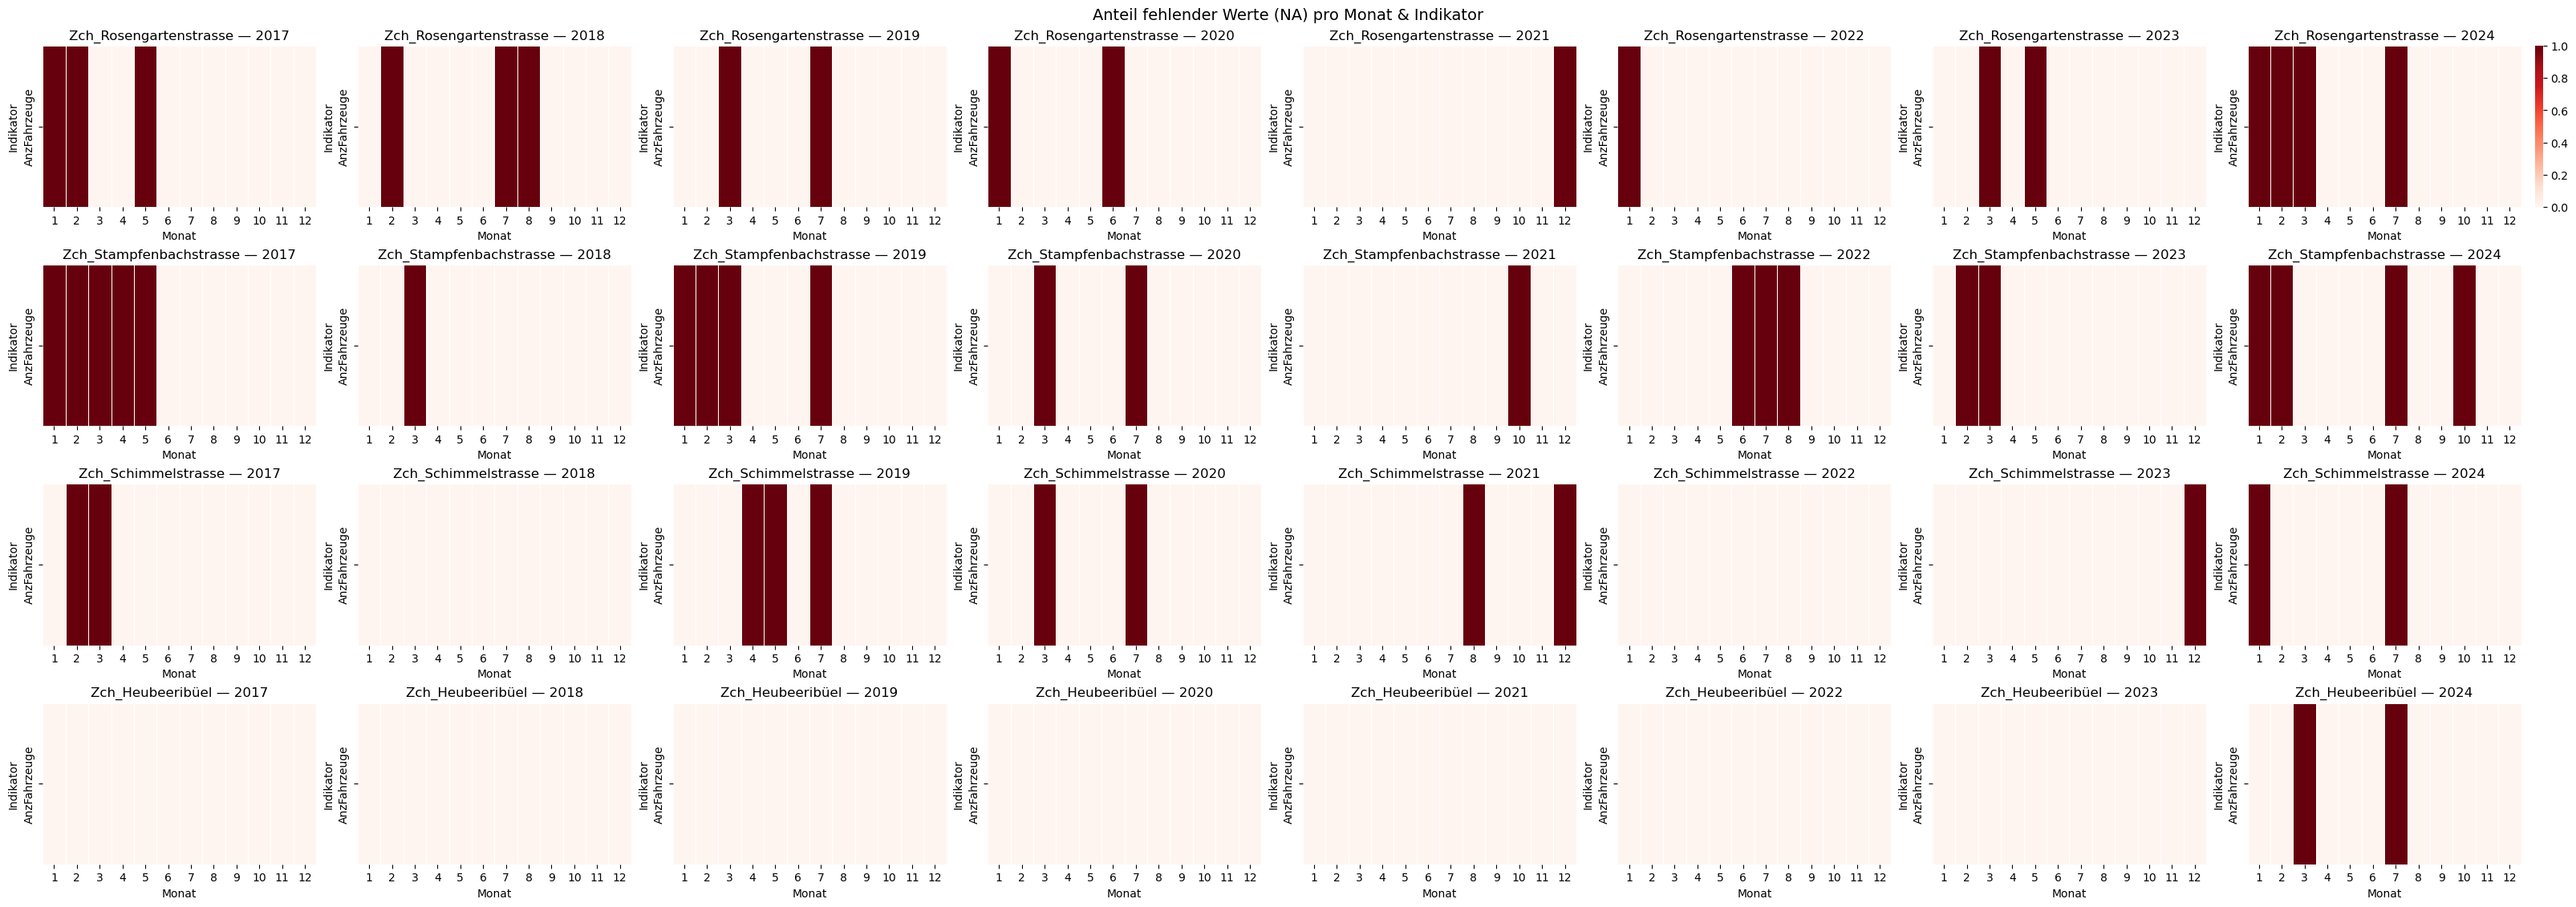

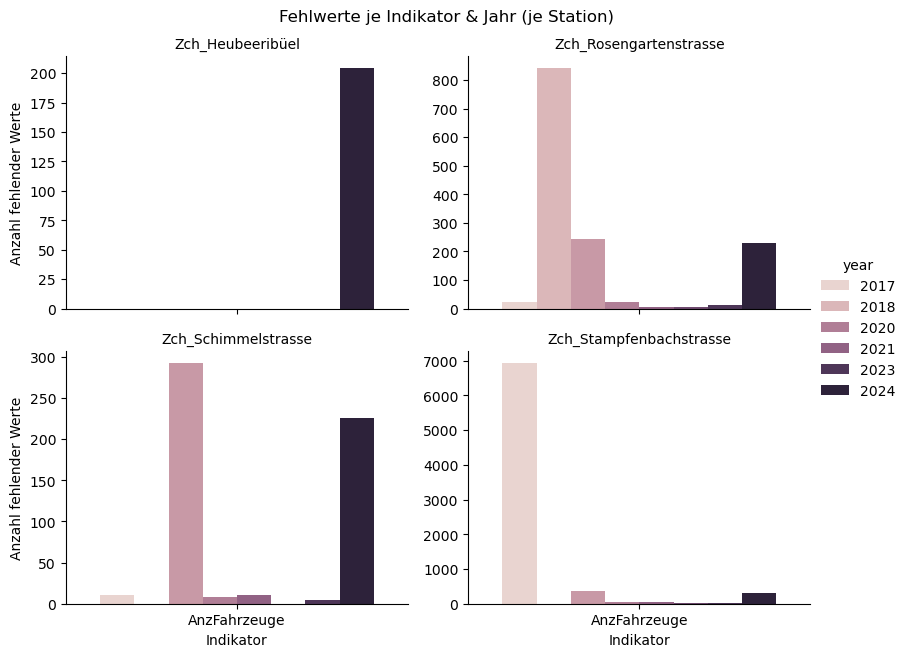

In [72]:
# =========================
# 1) Build a tidy 'missing' table
# =========================
key_cols = [c for c in ["Standort", "Datum_date", "Datum_time"] if c in df_traffic.columns]
parameters_cols = [c for c in df_traffic.columns if c not in key_cols]
# Melt to long format: one row per (keys, Parameter), with value column 'Wert'
long_vals = df_traffic.melt(
    id_vars=key_cols,
    value_vars=parameters_cols,
    var_name="Parameter",
    value_name="Wert"
)

# Keep only rows where the pollutant value is missing
na_long = long_vals[long_vals["Wert"].isna()].drop(columns="Wert").reset_index(drop=True)
na_long

# Choose your parameters & stations
PARAMS = ["AnzFahrzeuge"]  # adjust to taste
stations_all = na_long["Standort"].unique().tolist()
STATIONS5 = stations_all[:4]  # or explicitly pick the four you want

# Prepare year/month
na_long["date_ts"] = pd.to_datetime(na_long["Datum_date"], errors="coerce")
na_long["year"] = na_long["date_ts"].dt.year
na_long["month"] = na_long["date_ts"].dt.month

# Filter to desired subset
miss_sub = na_long[na_long["Standort"].isin(STATIONS5) & na_long["Parameter"].isin(PARAMS)].copy()

# 1) Monthly heatmap: missing rate per (station, year, month, parameter)
# We need denominators (how many expected rows per month) — in a daily matrix it’s one per day, in hourly 24/day.
# Using `mean` of boolean is fine if your pivot has one row per day; if hourly, it is fraction of hours missing in that month.

monthly_rate = (
    miss_sub.groupby(["Standort", "year", "month", "Parameter"], dropna=True)
            .size()                              # count of missing entries
            .reset_index(name="missing_count")
)

# To get rates, we need total expected entries per (station, year, month, parameter).
# If the pivot is daily with one row per day per station, total days per month:
days_per_month = (
    na_long.groupby(["Standort", "year", "month"])
           .size()
           .reset_index(name="total_rows_month")  # total rows across all params; we'll assume same for each param
)

monthly_rate = monthly_rate.merge(days_per_month, on=["Standort", "year", "month"], how="left")
monthly_rate["missing_rate"] = monthly_rate["missing_count"] / monthly_rate["total_rows_month"]

# Fill in missing combinations to show zeros in the heatmap
full_index = pd.MultiIndex.from_product(
    [STATIONS5, sorted(miss_sub["year"].dropna().unique()), range(1,13), PARAMS],
    names=["Standort", "year", "month", "Parameter"]
).to_frame(index=False)

monthly_rate = full_index.merge(monthly_rate,
                                on=["Standort", "year", "month", "Parameter"],
                                how="left").fillna({"missing_rate": 0.0})

# Plot grid: rows = stations, cols = years
years_sorted = sorted(monthly_rate["year"].unique())
nrows, ncols = len(STATIONS5), len(years_sorted)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,
                         figsize=(4*ncols, 2.8*nrows), constrained_layout=True)

# Ensure axes is 2D
if nrows == 1 and ncols == 1:
    axes = np.array([[axes]])
elif nrows == 1:
    axes = axes.reshape(1, -1)

for i, st in enumerate(STATIONS5):
    for j, yr in enumerate(years_sorted):
        ax = axes[i, j]
        mat = (
            monthly_rate[(monthly_rate["Standort"] == st) & (monthly_rate["year"] == yr)]
            .pivot(index="Parameter", columns="month", values="missing_rate")
            .reindex(index=PARAMS)
        )
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap="Reds",
                    cbar=(i==0 and j==ncols-1), linewidths=0.5, linecolor="white")
        ax.set_title(f"{st} — {yr}")
        ax.set_xlabel("Monat")
        ax.set_ylabel("Indikator")
        ax.set_xticklabels([str(m) for m in range(1, 13)], rotation=0)

fig.suptitle("Anteil fehlender Werte (NA) pro Monat & Indikator", fontsize=14)
plt.show()

# 2) Grouped bar chart: counts per pollutant per station, hue = year
counts = (
    miss_sub.groupby(["Standort", "Parameter", "year"], dropna=True)
            .size()
            .reset_index(name="missing_count")
)

g = sns.catplot(
    data=counts, x="Parameter", y="missing_count", hue="year", col="Standort",
    kind="bar", col_wrap=2, sharey=False, height=3.2, aspect=1.3
)
g.set_titles("{col_name}")
g.set_axis_labels("Indikator", "Anzahl fehlender Werte")
plt.suptitle("Fehlwerte je Indikator & Jahr (je Station)", y=1.02)
plt.show()

In [74]:
# check time during summer time
df_traffic.loc[df_traffic['Datetime'].dt.date == pd.to_datetime('2024-06-18').date(), 'Datetime']

11715070   2024-06-18 00:00:00
11715071   2024-06-18 01:00:00
11715072   2024-06-18 02:00:00
11715073   2024-06-18 03:00:00
11715074   2024-06-18 04:00:00
                   ...        
12845345   2024-06-18 19:00:00
12845346   2024-06-18 20:00:00
12845347   2024-06-18 21:00:00
12845348   2024-06-18 22:00:00
12845349   2024-06-18 23:00:00
Name: Datetime, Length: 192, dtype: datetime64[ns]

In [75]:
df_traffic.to_csv("data/traffic_h1_17_24.csv", index=False)